# 02 — Phase 2 · Baselines (Benign / DDoS)

## Question
Before comparing anything complex: how well do a floor model, a linear model
and a tree ensemble do on the binary task, with the leak-free split?

## Protocol
- Deduped CIC-DDoS2019, 77 features, 80/20 stratified split on the
  fine-grained family target, seed 42.
- `DummyClassifier(strategy="stratified")` is the floor.
- `LogisticRegression(max_iter=2000, class_weight="balanced")` is the linear
  reference.
- `RandomForestClassifier(n_estimators=300, class_weight="balanced")` is the
  non-linear reference.
- Scaling and constant-feature removal are inside the pipeline, fitted on
  train only.
- Metrics: Macro-F1, Weighted-F1, per-class Precision/Recall/F1, PR-AUC,
  ROC-AUC, FPR at 95 % recall.  Accuracy is shown but not used to conclude.

The numbers below are produced by `uv run daf-projet baseline`; this notebook
loads `results/baseline_binary.csv` so it does not silently retrain on a
different split.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split

from daf_projet.data import group_attack_families, split
from daf_projet.experiments.common import load_deduped

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120

ROOT = Path.cwd()
if not (ROOT / "dataset").exists():
    ROOT = ROOT.parent
RES = ROOT / "results"
FIG = ROOT / "figures"

results = pd.read_csv(RES / "baseline_binary.csv")
per_class = pd.read_csv(RES / "baseline_binary_per_class.csv")
display(results[["model", "macro_f1", "weighted_f1", "accuracy", "pr_auc", "roc_auc", "fpr", "fpr_at_tpr95", "fit_seconds", "n_features_effective"]].round(4))
print("sklearn:", results["sklearn_version"].unique().tolist())

,model,macro_f1,weighted_f1,accuracy,pr_auc,roc_auc,fpr,fpr_at_tpr95,fit_seconds,n_features_effective
0,dummy,0.5006,0.6507,0.6508,0.7741,0.5006,0.7736,0.9497,0.4774,65
1,logreg,0.9949,0.9964,0.9964,0.9998,0.9994,0.0026,0.0001,4.7950,65
2,random_forest,0.9991,0.9994,0.9994,1.0000,1.0000,0.0003,0.0000,24.4419,65


sklearn: ['1.9.1']


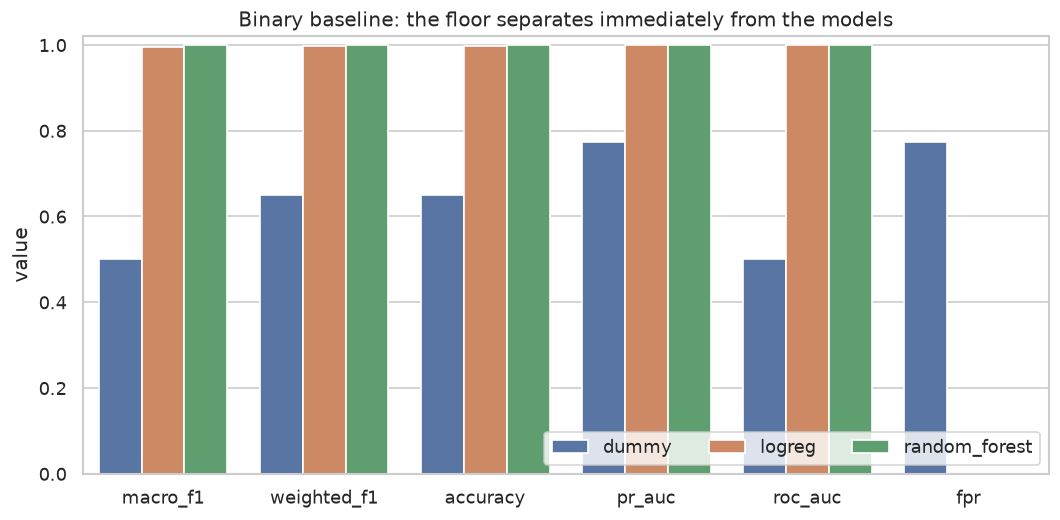

,macro_f1,pr_auc,roc_auc,fpr,fpr_at_tpr95
model,,,,,
dummy,0.5006,0.7741,0.5006,0.7736,0.9497
logreg,0.9949,0.9998,0.9994,0.0026,0.0001
random_forest,0.9991,1.0000,1.0000,0.0003,0.0000


In [2]:
metrics_long = results.melt(
    id_vars=["model"],
    value_vars=["macro_f1", "weighted_f1", "accuracy", "pr_auc", "roc_auc", "fpr"],
    var_name="metric",
    value_name="value",
)
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=metrics_long, x="metric", y="value", hue="model", ax=ax)
ax.set_ylim(0, 1.02)
ax.set_title("Binary baseline: the floor separates immediately from the models")
ax.set_xlabel("")
ax.legend(title="", ncol=3, loc="lower right")
fig.tight_layout()
fig.savefig(FIG / "02_baseline_metrics.png", bbox_inches="tight")
plt.show()

display(
    results[["model", "macro_f1", "pr_auc", "roc_auc", "fpr", "fpr_at_tpr95"]]
    .set_index("model")
    .round(4)
)

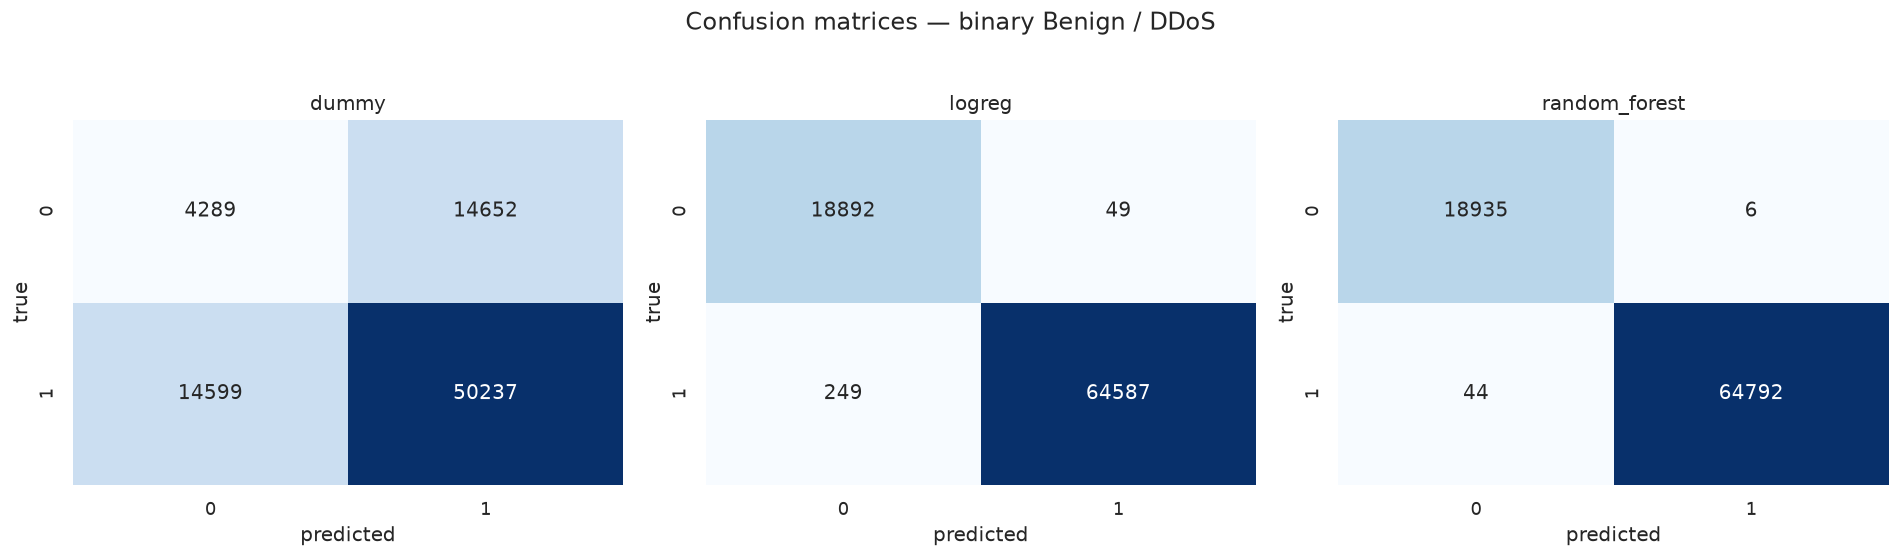

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, model in zip(axes, ["dummy", "logreg", "random_forest"]):
    matrix = pd.read_csv(RES / f"baseline_confusion_{model}.csv", index_col=0)
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(model)
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")
fig.suptitle("Confusion matrices — binary Benign / DDoS", y=1.03)
fig.tight_layout()
fig.savefig(FIG / "02_baseline_confusion.png", bbox_inches="tight")
plt.show()

In [4]:
# Label-alignment sanity check: on the full data the stratified dummy reaches
# Macro-F1 ~ 1/13, the chance level for 13 classes.  Accuracy tracks
# sum(prior^2), not 1/13, because the classes are imbalanced.  A capped run can
# give a different dummy Macro-F1 because the cap changes the class priors.
X, y_family, _, _ = load_deduped()
X_train, X_test, y_family_train, y_family_test = split(X, y_family, seed=42)
y_train = group_attack_families(y_family_train)
y_test = group_attack_families(y_family_test)

dummy = DummyClassifier(strategy="stratified", random_state=42)
dummy.fit(X_train, y_train)
pred = dummy.predict(X_test)
prior = y_train.value_counts(normalize=True)
print(f"classes                : {y_train.nunique()}")
print(f"1 / n_classes          : {1 / y_train.nunique():.4f}")
print(f"sum(prior^2) (accuracy): {(prior**2).sum():.4f}")
print(f"Dummy accuracy         : {accuracy_score(y_test, pred):.4f}")
print(f"Dummy Macro-F1         : {f1_score(y_test, pred, average='macro', zero_division=0):.4f}")
print("Labels are aligned: dummy accuracy tracks sum(prior^2), not a collapsed label.")

classes                : 13
1 / n_classes          : 0.0769
sum(prior^2) (accuracy): 0.2092


Dummy accuracy         : 0.2082


Dummy Macro-F1         : 0.0763
Labels are aligned: dummy accuracy tracks sum(prior^2), not a collapsed label.


## Reading the result

**Check.** On the full data the 13-class dummy reaches Macro-F1 ≈ 0.076 ≈
1/13, and its accuracy tracks sum(prior²) ≈ 0.208.  Labels are aligned.  The
binary dummy floor is ≈ 0.50, as expected for an imbalanced two-class test.

**Observation.** Logistic regression and random forest both exceed 0.99
Macro-F1 on the binary task; the dummy floor is around 0.5 because the test set
is imbalanced toward attacks.  The gap between models is tiny compared with the
gap to the floor.

**Interprétation ML.** Benign/DDoS is an easy problem on this dataset: a linear
boundary already captures it.  A near-perfect binary score is therefore not
evidence that the model understands attack *types*.  Experiment 1 changes only
the target and keeps the same rows, models and seed.

**Interprétation cyber.** A binary detector with FPR below 1 % is operationally
useful as a first-stage alarm, but it cannot tell an analyst which mitigation to
apply.  The next question is whether the same flow representation survives when
the label set becomes 13 classes.

**Limite.** The test set is a random split of a 2019 lab capture.  It does not
measure drift, adversarial evasion or encrypted traffic.  Accuracy is reported,
but the conclusions rest on Macro-F1, per-class recall and FPR.